# Advanced Analysis

#### Mahalanobis Distances
- Multi-dimensional representation of z-score
- Replace univariate mean with multivariate mean
- Replace standard deviation with covariance matrix

Univariate Z-score:
$$z_i=\frac{x_i-\bar{x}}{s} $$
Mahalanobis Distance:
$$D = \sqrt{(x-\mu)^T\sum\ ^{-1}(x-\mu)}$$
Minimum Covariance Determinant:
$$D_M = \sqrt{(x-\mu_{MCD})^T\sum\ ^{-1}(x-\mu)}$$

In [80]:
# ML libaries

from sys import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression

from scipy.spatial import distance
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [81]:
path = "/home/user1/codingProjects/Fault_Detection_Fall2026/data/processed/Exercise5.csv"
df = pd.read_csv(path)

df.head()

,IA,IB,IC,IP,IG,VA(kV),VB(kV),VC(kV),VS(kV),V1MEM,...,ICL,IAX,IBX,ICX,IAY,IBY,ICY,IAT,IBT,ICT
0,131.0,-206.0,46.0,-12.0,-29.0,-62.2,90.8,-29.9,-60.5,0.0,...,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0
1,51.0,-211.0,123.0,-7.0,-36.0,-31.2,92.0,-59.3,-33.7,0.0,...,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0
2,-14.0,-186.0,168.0,-7.0,-32.0,4.8,77.8,-84.1,7.4,0.0,...,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0
3,-102.0,-124.0,194.0,-8.0,-32.0,39.1,53.6,-92.6,36.8,0.0,...,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0
4,-158.0,-60.0,189.0,-10.0,-28.0,70.1,17.7,-88.4,71.7,-0.1,...,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0,-99999.0


In [82]:
## Data Preprocessing

# keep only columns 0 to 2 and 5 to 7
df = df.iloc[:, [0, 1, 2, 5, 6, 7]]
df.head()

,IA,IB,IC,VA(kV),VB(kV),VC(kV)
0,131.0,-206.0,46.0,-62.2,90.8,-29.9
1,51.0,-211.0,123.0,-31.2,92.0,-59.3
2,-14.0,-186.0,168.0,4.8,77.8,-84.1
3,-102.0,-124.0,194.0,39.1,53.6,-92.6
4,-158.0,-60.0,189.0,70.1,17.7,-88.4


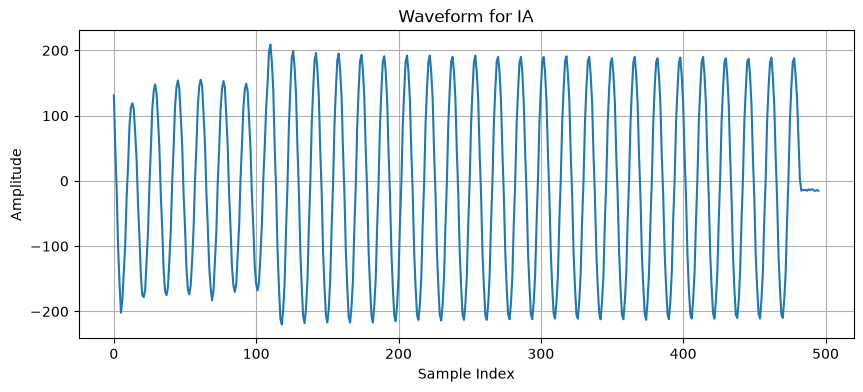

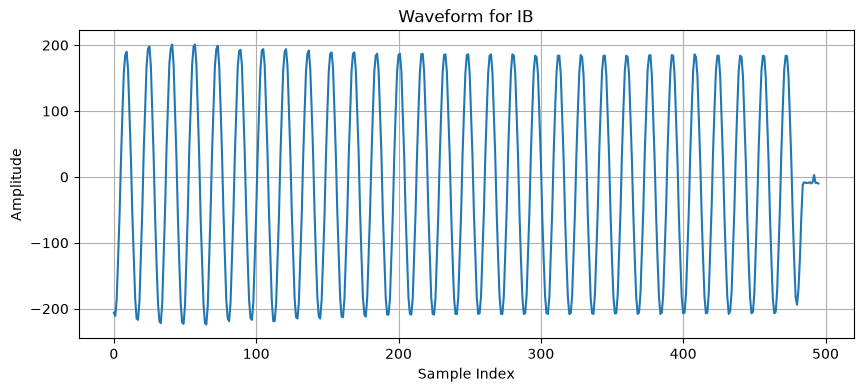

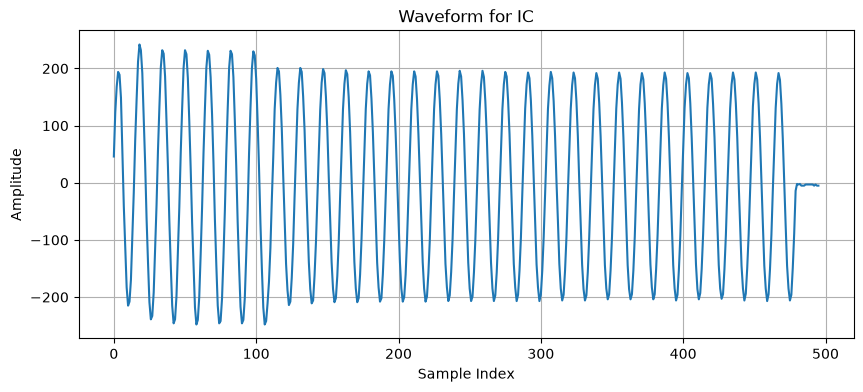

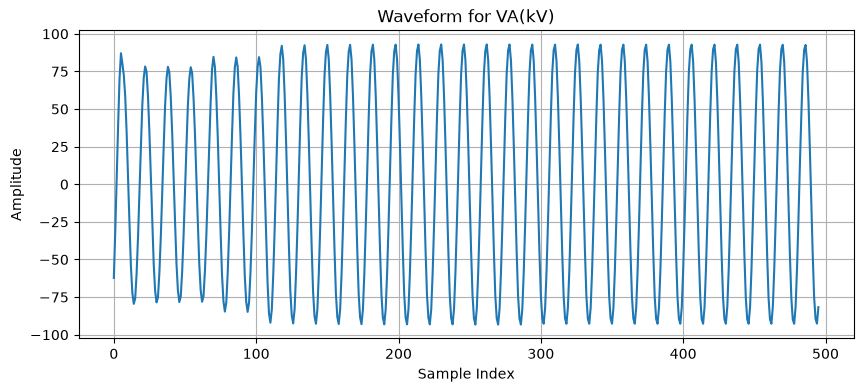

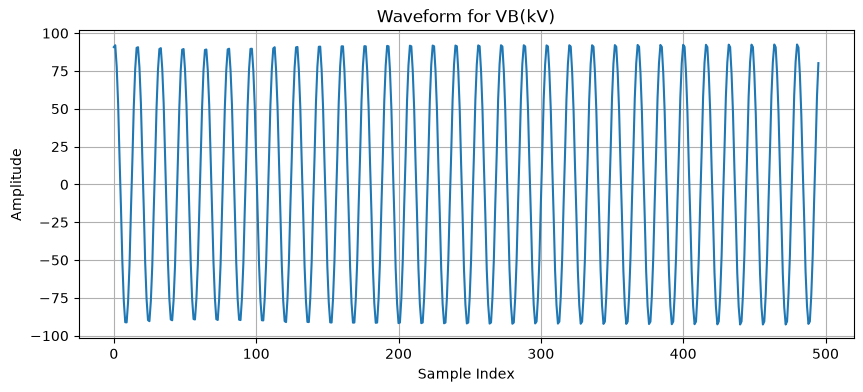

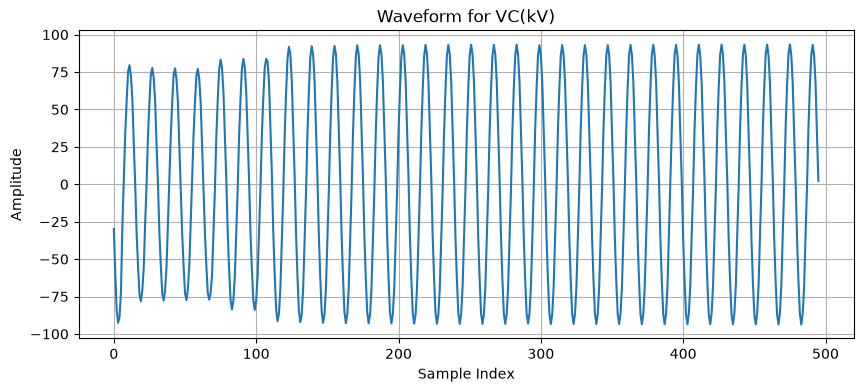

In [83]:
# plot waveforms for each column
for col in df.columns[0:6]:
    plt.figure(figsize=(10, 4))
    plt.plot(df[col])
    plt.title(f'Waveform for {col}')
    plt.xlabel('Sample Index')
    plt.ylabel('Amplitude')
    plt.grid()
    plt.show()

## Windowed Mahalanobis Normal Model

Exercise5 is treated as real normal data. The model is trained on full-cycle windows before the suspicious tail and then scores every full-cycle window so the tail behavior can still be flagged.


In [84]:
# Window and training configuration
signal_columns = ['IA', 'IB', 'IC', 'VA(kV)', 'VB(kV)', 'VC(kV)']
samples_per_cycle = 16
window_size = samples_per_cycle
window_step = samples_per_cycle
train_end_sample = 464
threshold_quantile = 1.0

raw_df = pd.read_csv(path)
signal_df = raw_df[signal_columns].apply(pd.to_numeric, errors='coerce').dropna().reset_index(drop=True)

print(f"Signal samples: {len(signal_df)}")
print(f"Training samples: 0:{train_end_sample}")
signal_df.head()


Signal samples: 496
Training samples: 0:464


,IA,IB,IC,VA(kV),VB(kV),VC(kV)
0,131.0,-206.0,46.0,-62.2,90.8,-29.9
1,51.0,-211.0,123.0,-31.2,92.0,-59.3
2,-14.0,-186.0,168.0,4.8,77.8,-84.1
3,-102.0,-124.0,194.0,39.1,53.6,-92.6
4,-158.0,-60.0,189.0,70.1,17.7,-88.4


### Feature Extraction

The magnitude model uses one-cycle RMS values. The component-ratio model uses one-cycle fundamental phasors before computing sequence components, which avoids the invalid instantaneous-ratio behavior from the earlier version.


In [85]:
def rms(x):
    return np.sqrt(np.mean(np.asarray(x, dtype=float) ** 2))


def safe_ratio(num, den, eps=1e-12):
    return num / den if abs(den) > eps else 0.0


def fundamental_phasor(x, samples_per_cycle=16):
    x = np.asarray(x, dtype=float)
    n_complete = len(x) // samples_per_cycle * samples_per_cycle
    x = x[:n_complete]

    n = np.arange(len(x))
    angle = 2j * np.pi * n / samples_per_cycle
    return np.sqrt(2) * np.mean(x * np.exp(angle))


def sequence_components(a_phase, b_phase, c_phase):
    alpha = np.exp(2j * np.pi / 3)
    zero = (a_phase + b_phase + c_phase) / 3
    positive = (a_phase + alpha * b_phase + alpha**2 * c_phase) / 3
    negative = (a_phase + alpha**2 * b_phase + alpha * c_phase) / 3
    return zero, positive, negative


def make_windows(data, window_size=16, step=16):
    rows = []
    for start in range(0, len(data) - window_size + 1, step):
        rows.append({
            'start_sample': start,
            'end_sample': start + window_size,
            'window': data.iloc[start:start + window_size].copy(),
        })
    return rows


def extract_magnitude_features(windows):
    rows = []
    metadata = []
    for item in windows:
        w = item['window']
        rows.append({
            'IA_rms': rms(w['IA']),
            'IB_rms': rms(w['IB']),
            'IC_rms': rms(w['IC']),
            'VA_rms_kv': rms(w['VA(kV)']),
            'VB_rms_kv': rms(w['VB(kV)']),
            'VC_rms_kv': rms(w['VC(kV)']),
        })
        metadata.append({
            'start_sample': item['start_sample'],
            'end_sample': item['end_sample'],
        })
    return pd.DataFrame(rows), pd.DataFrame(metadata)


def extract_component_ratio_features(windows, samples_per_cycle=16):
    rows = []
    metadata = []
    for item in windows:
        w = item['window']

        ia_ph = fundamental_phasor(w['IA'], samples_per_cycle)
        ib_ph = fundamental_phasor(w['IB'], samples_per_cycle)
        ic_ph = fundamental_phasor(w['IC'], samples_per_cycle)
        va_ph = fundamental_phasor(w['VA(kV)'], samples_per_cycle)
        vb_ph = fundamental_phasor(w['VB(kV)'], samples_per_cycle)
        vc_ph = fundamental_phasor(w['VC(kV)'], samples_per_cycle)

        i0, i1, i2 = sequence_components(ia_ph, ib_ph, ic_ph)
        v0, v1, v2 = sequence_components(va_ph, vb_ph, vc_ph)

        rows.append({
            'I0_I1': safe_ratio(abs(i0), abs(i1)),
            'I2_I1': safe_ratio(abs(i2), abs(i1)),
            'V0_V1': safe_ratio(abs(v0), abs(v1)),
            'V2_V1': safe_ratio(abs(v2), abs(v1)),
        })
        metadata.append({
            'start_sample': item['start_sample'],
            'end_sample': item['end_sample'],
        })
    return pd.DataFrame(rows), pd.DataFrame(metadata)


### Mahalanobis Helpers


In [86]:
def fit_mahalanobis(features, threshold_quantile=1.0):
    values = np.asarray(features, dtype=float)
    mean_vector = values.mean(axis=0)
    cov_matrix = np.cov(values, rowvar=False)
    inv_cov_matrix = np.linalg.pinv(cov_matrix)

    train_distances = mahalanobis_distance(features, mean_vector, inv_cov_matrix)
    threshold = np.quantile(train_distances, threshold_quantile)

    return {
        'mean_vector': mean_vector,
        'cov_matrix': cov_matrix,
        'inv_cov_matrix': inv_cov_matrix,
        'threshold': threshold,
        'threshold_quantile': threshold_quantile,
        'feature_columns': list(features.columns),
    }


def mahalanobis_distance(features, mean_vector, inv_cov_matrix):
    values = np.asarray(features, dtype=float)
    diff = values - mean_vector
    squared = np.sum(diff @ inv_cov_matrix * diff, axis=1)
    return np.sqrt(np.maximum(squared, 0.0))


def score_mahalanobis(features, model):
    distances = mahalanobis_distance(
        features[model['feature_columns']],
        model['mean_vector'],
        model['inv_cov_matrix'],
    )
    result = features.copy()
    result['mahalanobis_distance'] = distances
    result['threshold'] = model['threshold']
    result['is_anomaly'] = result['mahalanobis_distance'] > result['threshold']
    return result


### Magnitude Model


In [87]:
windows = make_windows(signal_df, window_size=window_size, step=window_step)
magnitude_features, window_metadata = extract_magnitude_features(windows)
train_mask = window_metadata['end_sample'].le(train_end_sample)

magnitude_model = fit_mahalanobis(
    magnitude_features.loc[train_mask],
    threshold_quantile=threshold_quantile,
)

magnitude_scores = pd.concat(
    [window_metadata, score_mahalanobis(magnitude_features, magnitude_model)],
    axis=1,
)

print(f"Magnitude model threshold ({threshold_quantile:.0%} train quantile): {magnitude_model['threshold']:.3f}")
print(f"Training windows: {train_mask.sum()} / {len(magnitude_scores)}")
magnitude_scores


Magnitude model threshold (100% train quantile): 4.764
Training windows: 29 / 31


,start_sample,end_sample,IA_rms,IB_rms,IC_rms,VA_rms_kv,VB_rms_kv,VC_rms_kv,mahalanobis_distance,threshold,is_anomaly
0,0,16,114.670997,144.617599,142.583528,59.221037,65.785646,60.883131,4.763917,4.763917,False
1,16,32,118.518722,150.152006,170.229991,55.655593,65.207616,55.247749,3.813159,4.763917,False
2,32,48,118.160114,152.126592,169.367389,55.385298,64.857180,54.850467,2.939540,4.763917,False
3,48,64,118.091860,153.053912,169.752577,55.154476,64.534782,54.704210,3.571375,4.763917,False
4,64,80,118.368334,151.385477,170.343036,58.894800,64.464229,57.684508,4.569528,4.763917,False
5,80,96,114.285006,148.715962,169.967644,59.667694,64.657289,59.289322,3.850936,4.763917,False
6,96,112,130.839596,148.823511,174.801852,61.721056,64.775685,60.540276,4.294130,4.763917,False
7,112,128,148.747059,148.904542,147.581334,65.259137,65.224109,65.019761,3.370139,4.763917,False
8,128,144,146.570589,146.662026,146.230554,65.554357,65.445263,65.493964,2.418196,4.763917,False
9,144,160,146.084522,146.078532,145.253227,65.741825,65.662361,65.685158,2.006454,4.763917,False


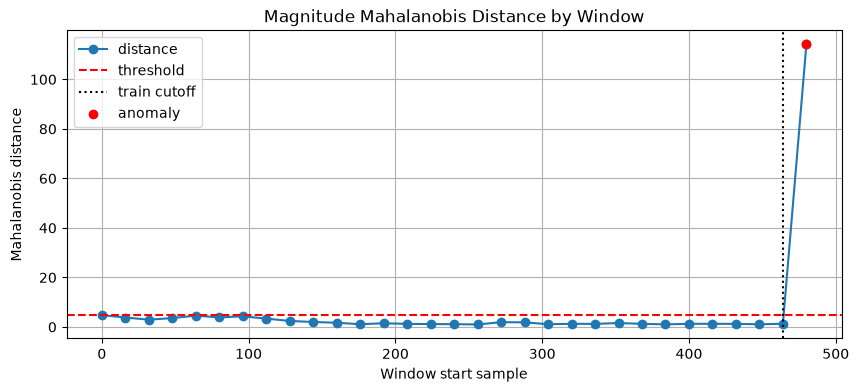

Magnitude anomalies:
    start_sample  end_sample  mahalanobis_distance  threshold
30           480         496            114.085976   4.763917


In [88]:
plt.figure(figsize=(10, 4))
plt.plot(magnitude_scores['start_sample'], magnitude_scores['mahalanobis_distance'], marker='o', label='distance')
plt.axhline(magnitude_model['threshold'], color='red', linestyle='--', label='threshold')
plt.axvline(train_end_sample, color='black', linestyle=':', label='train cutoff')
plt.scatter(
    magnitude_scores.loc[magnitude_scores['is_anomaly'], 'start_sample'],
    magnitude_scores.loc[magnitude_scores['is_anomaly'], 'mahalanobis_distance'],
    color='red',
    zorder=3,
    label='anomaly',
)
plt.title('Magnitude Mahalanobis Distance by Window')
plt.xlabel('Window start sample')
plt.ylabel('Mahalanobis distance')
plt.grid()
plt.legend()
plt.show()

magnitude_anomalies = magnitude_scores[magnitude_scores['is_anomaly']]
print('Magnitude anomalies:')
print(magnitude_anomalies[['start_sample', 'end_sample', 'mahalanobis_distance', 'threshold']])


### Component-Ratio Model


In [89]:
component_ratio_features, component_metadata = extract_component_ratio_features(
    windows,
    samples_per_cycle=samples_per_cycle,
)

component_model = fit_mahalanobis(
    component_ratio_features.loc[train_mask],
    threshold_quantile=threshold_quantile,
)

component_scores = pd.concat(
    [component_metadata, score_mahalanobis(component_ratio_features, component_model)],
    axis=1,
)

print(f"Component-ratio model threshold ({threshold_quantile:.0%} train quantile): {component_model['threshold']:.3f}")
print(f"Training windows: {train_mask.sum()} / {len(component_scores)}")
component_scores


Component-ratio model threshold (100% train quantile): 3.883
Training windows: 29 / 31


,start_sample,end_sample,I0_I1,I2_I1,V0_V1,V2_V1,mahalanobis_distance,threshold,is_anomaly
0,0,16,0.009655,0.148584,0.000434,0.067655,3.246207,3.883289,False
1,16,32,0.015775,0.219492,0.000807,0.115484,3.285436,3.883289,False
2,32,48,0.014759,0.210137,0.000913,0.116065,3.418155,3.883289,False
3,48,64,0.012310,0.211908,0.000689,0.114717,3.330658,3.883289,False
4,64,80,0.009887,0.213104,0.000605,0.071488,2.434686,3.883289,False
5,80,96,0.011041,0.231644,0.000589,0.057950,3.883289,3.883289,False
6,96,112,0.008098,0.175521,0.000527,0.041819,2.853635,3.883289,False
7,112,128,0.007240,0.006120,0.000510,0.002235,0.632625,3.883289,False
8,128,144,0.005614,0.005311,0.000576,0.000461,2.106594,3.883289,False
9,144,160,0.007512,0.006770,0.000465,0.000381,0.779621,3.883289,False


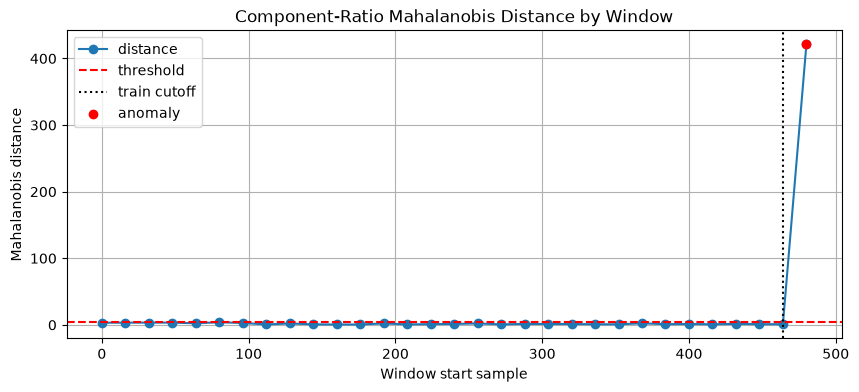

Component-ratio anomalies:
    start_sample  end_sample  mahalanobis_distance  threshold
30           480         496            420.974834   3.883289


In [90]:
plt.figure(figsize=(10, 4))
plt.plot(component_scores['start_sample'], component_scores['mahalanobis_distance'], marker='o', label='distance')
plt.axhline(component_model['threshold'], color='red', linestyle='--', label='threshold')
plt.axvline(train_end_sample, color='black', linestyle=':', label='train cutoff')
plt.scatter(
    component_scores.loc[component_scores['is_anomaly'], 'start_sample'],
    component_scores.loc[component_scores['is_anomaly'], 'mahalanobis_distance'],
    color='red',
    zorder=3,
    label='anomaly',
)
plt.title('Component-Ratio Mahalanobis Distance by Window')
plt.xlabel('Window start sample')
plt.ylabel('Mahalanobis distance')
plt.grid()
plt.legend()
plt.show()

component_anomalies = component_scores[component_scores['is_anomaly']]
print('Component-ratio anomalies:')
print(component_anomalies[['start_sample', 'end_sample', 'mahalanobis_distance', 'threshold']])


### Combined Gate

A window is routed to the downstream simulated-fault classifier if either normal detector marks it anomalous.


In [91]:
anomaly_gate = window_metadata.copy()
anomaly_gate['magnitude_distance'] = magnitude_scores['mahalanobis_distance']
anomaly_gate['magnitude_threshold'] = magnitude_model['threshold']
anomaly_gate['magnitude_anomaly'] = magnitude_scores['is_anomaly']
anomaly_gate['component_distance'] = component_scores['mahalanobis_distance']
anomaly_gate['component_threshold'] = component_model['threshold']
anomaly_gate['component_anomaly'] = component_scores['is_anomaly']
anomaly_gate['route_to_classifier'] = anomaly_gate['magnitude_anomaly'] | anomaly_gate['component_anomaly']

print('Windows routed to classifier:')
print(anomaly_gate[anomaly_gate['route_to_classifier']])
anomaly_gate


Windows routed to classifier:
    start_sample  end_sample  magnitude_distance  magnitude_threshold  \
30           480         496          114.085976             4.763917   

    magnitude_anomaly  component_distance  component_threshold  \
30               True          420.974834             3.883289   

    component_anomaly  route_to_classifier  
30               True                 True  


,start_sample,end_sample,magnitude_distance,magnitude_threshold,magnitude_anomaly,component_distance,component_threshold,component_anomaly,route_to_classifier
0,0,16,4.763917,4.763917,False,3.246207,3.883289,False,False
1,16,32,3.813159,4.763917,False,3.285436,3.883289,False,False
2,32,48,2.939540,4.763917,False,3.418155,3.883289,False,False
3,48,64,3.571375,4.763917,False,3.330658,3.883289,False,False
4,64,80,4.569528,4.763917,False,2.434686,3.883289,False,False
5,80,96,3.850936,4.763917,False,3.883289,3.883289,False,False
6,96,112,4.294130,4.763917,False,2.853635,3.883289,False,False
7,112,128,3.370139,4.763917,False,0.632625,3.883289,False,False
8,128,144,2.418196,4.763917,False,2.106594,3.883289,False,False
9,144,160,2.006454,4.763917,False,0.779621,3.883289,False,False
